# Xarray und der Earth System Data Cube

**Ziele dieser Übung:**

* Xarray kennenlernen
* Den Earth System Data Cube (ESDC) öffnen und seine Metadaten lesen
  - Welche Variablen enthält der Cube?
  - Welche räumliche und zeitliche Auflösung hat er?
* Den Cube auf Variablen, Zeitraum und Region zuschneiden
* Mittelwerte berechnen und Daten darstellen

*(Hinweis: Diese Materialien orientieren sich am Kurs „Earth System Components“ von Miguel Mahecha und Milena Mönks an der Universität Leipzig.)*

---

## Was ist Xarray?

[Xarray](https://docs.xarray.dev/en/stable/index.html) ist ein Python-Package für **mehrdimensionale Daten mit Beschriftung**.
Es baut auf [NumPy](https://numpy.org/) auf.

In den Geowissenschaften gehört zu jedem Messwert ein Ort und eine Zeit.
Ein NumPy-Array kennt nur Positionen: Zeile 3, Spalte 5.
Xarray kennt die **Koordinaten**: Breitengrad, Längengrad, Datum.
Damit lassen sich Daten direkt über Ort und Zeit auswählen.

Formate wie `zarr` oder `netCDF` speichern Daten zusammen mit ihren Koordinaten und Metadaten.
Xarray kann diese Formate direkt lesen.

Xarray hat zwei Datenstrukturen ([Bildquelle](https://docs.xarray.dev/en/stable/user-guide/data-structures.html)):

![](https://docs.xarray.dev/en/stable/_images/dataset-diagram.png)

- **DataArray:** *eine* Variable mit ihren Dimensionen und Koordinaten, z. B. die Temperatur.
- **Dataset:** *mehrere* Variablen, die sich Koordinaten teilen. Der ganze Cube ist ein Dataset.

## Die wichtigste Regel: erst zuschneiden, dann rechnen

Der Earth System Data Cube ist **ca. 345 GB** groß.
Das VRE hat nur **3,5 GB Arbeitsspeicher**.

Das funktioniert trotzdem, weil Xarray **„lazy“** arbeitet:
Beim Öffnen werden nur die Metadaten gelesen.
Die eigentlichen Daten werden erst geladen, wenn sie wirklich gebraucht werden.
Das passiert beim Plotten, bei `.values`, `.load()` oder `.compute()`.

Deshalb immer in dieser Reihenfolge arbeiten:

1. **Variablen** auswählen
2. **Zeitraum** auswählen
3. **Region** oder **Punkt** auswählen
4. Erst dann **rechnen, laden und plotten**

Je kleiner der Ausschnitt, desto weniger Daten werden aus dem Internet geladen.
Der Code läuft dann schneller und der Arbeitsspeicher läuft nicht voll.
Eine einzelne globale Karte lädt z. B. schon rund 1 GB.
Ein Punkt oder eine kleine Region ist in wenigen Sekunden fertig.

**Achtung:** Befehle wie `.mean('time')` auf dem ganzen Cube können Stunden dauern oder abbrechen.

## Nachschlagen: die wichtigsten Befehle

Diese Übersicht dient zum Nachschlagen.
Alle Befehle werden weiter unten im Notebook an Beispielen gezeigt.
`ds` ist der ganze Cube (Dataset), `da` eine einzelne Variable (DataArray).

### Überblick verschaffen

```python
ds                         # Übersicht: Dimensionen, Koordinaten, Variablen
list(ds.data_vars)         # Namen aller Variablen
ds.attrs                   # Metadaten des Cubes
ds['ndvi'].attrs           # Metadaten einer Variablen (Einheit, Quelle, Zeitraum ...)
ds.nbytes / 1e9            # Größe in GB
```

### 1. Variablen auswählen

```python
da = ds['ndvi']                            # eine Variable → DataArray
da = ds.ndvi                               # gleiche Wirkung, kürzer
sub = ds[['ndvi', 'air_temperature_2m']]   # mehrere Variablen → Dataset (doppelte Klammern!)
```

### 2. Zeit auswählen

```python
da.sel(time='2007')                            # ein Jahr
da.sel(time='2007-05')                         # ein Monat
da.sel(time=slice('2005', '2010'))             # Zeitraum (Ende ist mit dabei)
da.sel(time='2007-05-10', method='nearest')    # Zeitschritt, der am nächsten liegt
da.sel(time=da.time.dt.month.isin([6, 7, 8]))  # nur Juni, Juli, August
da.isel(time=0)                                # nach Position: erster Zeitschritt
da.isel(time=-1)                               # nach Position: letzter Zeitschritt
```

### 3. Raum auswählen

**Achtung:** Im Cube läuft `lat` von Süd (-90) nach Nord (90) und `lon` von West (-180) nach Ost (180).
Deshalb: `slice(süd, nord)` und `slice(west, ost)`.
Bei falscher Reihenfolge ist das Ergebnis leer.

```python
da.sel(lat=slice(47, 55), lon=slice(5, 16))       # Region (Rechteck), hier Deutschland
da.sel(lat=51.08, lon=10.45, method='nearest')    # einzelner Punkt (nächste Gitterzelle)
```

**Achtung:** `method='nearest'` und `slice()` gehen nicht im selben `.sel()`.
Dann zwei `.sel()` hintereinander schreiben:

```python
da.sel(lat=slice(47, 55), lon=slice(5, 16)).sel(time='2010-07-01', method='nearest')
```

### Alles kombinieren und laden

```python
gpp_de = ds['gross_primary_productivity'].sel(
    time=slice('2010', '2015'),
    lat=slice(47, 55),
    lon=slice(5, 16),
)
gpp_de = gpp_de.load()   # erst jetzt wird geladen – nur der kleine Ausschnitt
```

### 4. Mittelwerte und Statistik

```python
da.mean('time')                     # Mittel über die Zeit → Karte
da.mean(['lat', 'lon'])             # Mittel über den Raum → Zeitreihe (ungewichtet)

gewichte = np.cos(np.deg2rad(da.lat))
da.weighted(gewichte).mean(['lat', 'lon'])   # flächengewichtetes Mittel → Zeitreihe

da.groupby('time.month').mean()     # mittlerer Jahresgang: 12 Werte (alle Januare, alle Februare, ...)
da.groupby('time.season').mean()    # Jahreszeiten: DJF, MAM, JJA, SON
da.groupby('time.year').mean()      # Jahresmittel: ein Wert pro Jahr
da.resample(time='1MS').mean()      # Monatsmittel: ein Wert pro Monat und Jahr
da.rolling(time=5, center=True).mean()   # gleitendes Mittel über 5 Zeitschritte

da.max('time'), da.min('time'), da.std('time'), da.median('time')
da.quantile(0.9, dim='time')        # 90. Perzentil
```

`groupby('time.month')` fasst **alle Jahre** zusammen. Das Ergebnis hat 12 Werte.
`resample(time='1MS')` bildet Mittel für **jeden einzelnen Monat**, z. B. Mai 2007, Juni 2007 usw.

Fehlende Werte (`NaN`) werden bei allen Funktionen automatisch übersprungen.

### Anomalien (Abweichung vom Normalzustand)

```python
klima = da.groupby('time.month').mean()        # mittlerer Jahresgang
anomalie = da.groupby('time.month') - klima    # Abweichung jedes Zeitschritts davon
```

### Masken und Filter

```python
da.where(da > 0.5)                 # Werte ≤ 0.5 werden zu NaN
temp.where(gpp.notnull())          # Temperatur nur dort, wo es GPP-Werte gibt (Land)
```

### Plotten

```python
da.isel(time=0).plot()                           # Karte
da.isel(time=0).plot(robust=True, cmap='YlGn')   # ohne Ausreißer, andere Farben
punkt.plot()                                     # Zeitreihe (DataArray nur mit Dimension time)
klima.plot(col='month', col_wrap=4)              # mehrere Karten nebeneinander
```

### Speichern und wieder öffnen

```python
gpp_de.to_netcdf('gpp_deutschland.nc')
gpp_de = xr.open_dataarray('gpp_deutschland.nc')
```

Im VRE bleibt der Home-Ordner erhalten. Dort gespeicherte Dateien sind auch nach einem Neustart noch da.

---

## 1. Vorbereitung

Für den Zugriff über das Internet braucht Xarray die Packages `aiohttp` und `requests`.
Die folgende Zelle installiert sie.
Ein `%` vor `pip` installiert direkt aus dem Notebook heraus.

**Im VRE:** Installierte Packages sind nach einem Neustart des VRE wieder weg.
Die Zelle muss dann erneut ausgeführt werden.

In [1]:
%pip install -q aiohttp requests zarr

Nun importieren wir die Packages.
`zarr` und `fsspec` müssen installiert sein, aber nicht importiert werden.
Xarray nutzt sie im Hintergrund.

In [2]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

## 2. Den Cube öffnen

Der Cube liegt im Format **Zarr** auf einem Server des Max-Planck-Instituts für Biogeochemie in Jena.
Zarr speichert große Arrays in kleinen, komprimierten Stücken (**Chunks**).
So lassen sich einzelne Ausschnitte laden, ohne die ganze Datei herunterzuladen.
Ähnliche Formate sind `netCDF` und `HDF5`.

`xr.open_dataset()` öffnet den Cube.
Wir speichern ihn in der Variablen `ds` (kurz für *Dataset*).

- `engine='zarr'` gibt das Format an.
- `chunks={}` sorgt dafür, dass nichts sofort geladen wird (*lazy loading*).

In [3]:
url = 'https://s3.bgc-jena.mpg.de:9000/esdl-esdc-v3.0.2/esdc-8d-0.25deg-256x128x128-3.0.2.zarr'

ds = xr.open_dataset(url, engine='zarr', chunks={})

/tmp/ipykernel_4098/633849383.py:3: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  ds = xr.open_dataset(url, engine='zarr', chunks={})


Den Cube gibt es in zwei Varianten mit unterschiedlichen Chunks:

| Datei endet auf | Chunks (Zeit × lat × lon) | gut für |
|---|---|---|
| `...256x128x128-3.0.2.zarr` | 256 × 128 × 128 | Zeitreihen, Regionen (diese Übung) |
| `...1x720x1440-3.0.2.zarr` | 1 × 720 × 1440 | einzelne globale Karten |

## 3. Überblick: Was steckt im Cube?

Die Ausgabe von `ds` zeigt Dimensionen, Koordinaten und Variablen.
Ein Klick auf das Dokument-Symbol rechts neben einer Variable zeigt ihre Metadaten.
Ein Klick auf das Zylinder-Symbol zeigt Größe und Chunks.

In [4]:
ds

<xarray.Dataset> Size: 345GB
Dimensions:                            (time: 1978, lat: 720, lon: 1440)
Coordinates:
  * time                               (time) datetime64[ns] 16kB 1979-01-05 ...
  * lat                                (lat) float64 6kB -89.88 -89.62 ... 89.88
  * lon                                (lon) float64 12kB -179.9 ... 179.9
Data variables: (12/42)
    aerosol_optical_thickness_550      (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    air_temperature_2m                 (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    bare_soil_evaporation              (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    burnt_area                         (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    cot                                (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    cth                                (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    ...                                 ...
    sif_rtsif                          (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    sm                                 (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    snow_sublimation                   (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    surface_moisture                   (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    terrestrial_ecosystem_respiration  (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
    transpiration                      (time, lat, lon) float32 8GB dask.array<chunksize=(256, 128, 128), meta=np.ndarray>
Attributes: (12/23)
    Conventions:                CF-1.9
    acknowledgment:             All ESDC data providers are acknowledged insi...
    contributor_name:           ['University of Leipzig', 'Max Planck Institu...
    contributor_url:            ['https://www.uni-leipzig.de/', 'https://www....
    creator_name:               ['University of Leipzig', 'Brockmann Consult ...
    creator_url:                ['https://www.uni-leipzig.de/', 'https://www....
    ...                         ...
    publisher_url:              https://www.earthsystemdatalab.net/
    time_coverage_end:          2021-12-31T00:00:00.000000000
    time_coverage_start:        1979-01-05T00:00:00.000000000
    time_period:                8D
    time_period_reported_day:   5.0
    title:                      Earth System Data Cube (ESDC) v3.0.1

In [5]:
print(f'Größe des Cubes: {ds.nbytes / 1e9:.0f} GB')
print(f'Anzahl Variablen: {len(ds.data_vars)}')
list(ds.data_vars)

Größe des Cubes: 345 GB
Anzahl Variablen: 42


['aerosol_optical_thickness_550',
 'air_temperature_2m',
 'bare_soil_evaporation',
 'burnt_area',
 'cot',
 'cth',
 'ctt',
 'evaporation',
 'evaporation_era5',
 'evaporative_stress',
 'gross_primary_productivity',
 'interception_loss',
 'kndvi',
 'latent_energy',
 'max_air_temperature_2m',
 'min_air_temperature_2m',
 'nbar_blue',
 'nbar_green',
 'nbar_nir',
 'nbar_red',
 'nbar_swir1',
 'nbar_swir2',
 'nbar_swir3',
 'ndvi',
 'net_ecosystem_exchange',
 'net_radiation',
 'nirv',
 'open_water_evaporation',
 'potential_evaporation',
 'precipitation_era5',
 'radiation_era5',
 'root_moisture',
 'sensible_heat',
 'sif_gome2_jj',
 'sif_gome2_pk',
 'sif_gosif',
 'sif_rtsif',
 'sm',
 'snow_sublimation',
 'surface_moisture',
 'terrestrial_ecosystem_respiration',
 'transpiration']

Die Metadaten stehen in `.attrs`. Das ist ein Dictionary.

In [6]:
ds.attrs

{'Conventions': 'CF-1.9',
 'acknowledgment': 'All ESDC data providers are acknowledged inside each variable',
 'contributor_name': ['University of Leipzig',
  'Max Planck Institute',
  'Brockmann Consult GmbH'],
 'contributor_url': ['https://www.uni-leipzig.de/',
  'https://www.mpg.de/en',
  'https://www.brockmann-consult.de/'],
 'creator_name': ['University of Leipzig', 'Brockmann Consult GmbH'],
 'creator_url': ['https://www.uni-leipzig.de/',
  'https://www.brockmann-consult.de/'],
 'date_modified': '2022-11-25 23:13:03.350030',
 'geospatial_lat_max': 89.875,
 'geospatial_lat_min': -89.875,
 'geospatial_lat_resolution': 0.25,
 'geospatial_lon_max': 179.875,
 'geospatial_lon_min': -179.875,
 'geospatial_lon_resolution': 0.25,
 'id': 'esdc-8d-0.25deg-256x128x128-3.0.1',
 'license': 'Terms and conditions of the DeepESDL data distribution',
 'project': 'DeepESDL',
 'publisher_name': 'DeepESDL Team',
 'publisher_url': 'https://www.earthsystemdatalab.net/',
 'time_coverage_end': '2021-12-3

**Aufgabe:**

1. Welche räumliche und zeitliche Auflösung hat der Cube?
2. Welche Einheit hat die Variable `air_temperature_2m`?
3. Welchen Zeitraum deckt diese Variable ab?
4. Für welchen Zeitraum gibt es `gross_primary_productivity`?

*Tipp:* `ds.attrs` und `ds['variablenname'].attrs` ansehen.

In [7]:
print(ds.time_period)
print(ds.geospatial_lat_resolution)
print(ds.air_temperature_2m.attrs['units'])

8D
0.25
°C


**Lösung:** Erst selbst versuchen! Dann links auf die Zelle klicken, um den Code anzuzeigen.

In [8]:
# 1. Auflösung
print('Räumlich:', ds.attrs['geospatial_lat_resolution'], 'Grad')   # 0.25° ≈ 28 km am Äquator
print('Zeitlich:', ds.attrs['time_period'])                         # 8D = 8 Tage

# 2. und 3. Lufttemperatur
t2m = ds['air_temperature_2m']
print('Einheit:', t2m.attrs['units'])
print('Zeitraum:', t2m.attrs['time_coverage_start'][:10], 'bis', t2m.attrs['time_coverage_end'][:10])

# 4. GPP
gpp = ds['gross_primary_productivity']
print('GPP:', gpp.attrs['time_coverage_start'][:10], 'bis', gpp.attrs['time_coverage_end'][:10])

Räumlich: 0.25 Grad
Zeitlich: 8D
Einheit: °C
Zeitraum: 1979-01-01 bis 2021-12-27
GPP: 2001-01-05 bis 2020-12-30


Die Zeitachse des Cubes reicht von 1979 bis 2021.
Nicht jede Variable deckt diesen ganzen Zeitraum ab.
Außerhalb ihres Zeitraums enthält eine Variable nur `NaN`.

## 4. DataArrays

Eine einzelne Variable holen wir mit eckigen Klammern oder mit einem Punkt aus dem Dataset.
Das Ergebnis ist ein **DataArray**.

In [9]:
ds['air_temperature_2m']   # oder kürzer: ds.air_temperature_2m

<xarray.DataArray 'air_temperature_2m' (time: 1978, lat: 720, lon: 1440)> Size: 8GB
dask.array<open_dataset-air_temperature_2m, shape=(1978, 720, 1440), dtype=float32, chunksize=(256, 128, 128), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 16kB 1979-01-05 1979-01-13 ... 2021-12-31
  * lat      (lat) float64 6kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
Attributes: (12/25)
    acknowledgment:             ERA5 hourly data on single levels from 1959 t...
    date_modified:              2022-11-04 15:41:36.233472
    description:                ERA5 Reanalysis Products
    geospatial_lat_max:         89.875
    geospatial_lat_min:         -89.875
    geospatial_lat_resolution:  0.25
    ...                         ...
    standard_name:              mean_air_temperature_2m
    temporal_resolution:        8D
    time_coverage_end:          2021-12-27T00:00:00.000000000
    time_coverage_start:        1979-01-01T00:00:00.000000000
    time_period:                8D
    units:                      °C

Ein DataArray besteht aus:

* `.dims`: Namen der Dimensionen, hier `time`, `lat`, `lon`
* `.coords`: Koordinaten für jede Dimension
* `.attrs`: Metadaten als Dictionary
* `.values`: die eigentlichen Werte als NumPy-Array

**Achtung:** `.values` lädt alle Daten in den Arbeitsspeicher.
Für eine ganze Variable sind das 8 GB. Das VRE stürzt dann ab.
`.values` daher nur auf kleinen Ausschnitten benutzen.

In [10]:
t2m = ds['air_temperature_2m']

print(t2m.dims)
print(t2m.attrs['units'])
print(f'{t2m.nbytes / 1e9:.1f} GB')

('time', 'lat', 'lon')
°C
8.2 GB


## 5. Den Cube zuschneiden

Für die Auswahl gibt es zwei Methoden:

- `.sel()` wählt nach **Koordinaten** aus, z. B. Datum oder Breitengrad. Das ist meist einfacher.
- `.isel()` wählt nach **Position** aus, z. B. den 1001. Zeitschritt. Wie bei NumPy beginnt die Zählung bei 0.

### 5.1 Zeit

In [11]:
# alle Zeitschritte im Mai 2003
ds['gross_primary_productivity'].sel(time='2003-05')

<xarray.DataArray 'gross_primary_productivity' (time: 4, lat: 720, lon: 1440)> Size: 17MB
dask.array<getitem, shape=(4, 720, 1440), dtype=float32, chunksize=(4, 128, 128), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 32B 2003-05-05 2003-05-13 ... 2003-05-29
  * lat      (lat) float64 6kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
Attributes: (12/25)
    acknowledgment:             FLUXCOM
    date_modified:              2022-10-17 22:14:30.401506
    description:                FLUXCOM
    geospatial_lat_max:         89.87499928049999
    geospatial_lat_min:         -89.8750000005
    geospatial_lat_resolution:  0.25
    ...                         ...
    standard_name:              gross_primary_productivity_of_carbon
    temporal_resolution:        8D
    time_coverage_end:          2020-12-30T00:00:00.000000000
    time_coverage_start:        2001-01-05T00:00:00.000000000
    time_period:                8D
    units:                      g C m^-2 d^-1

In [12]:
# Position 1000 = 1001. Zeitschritt (hier 3. Oktober 2000)
ds['air_temperature_2m'].isel(time=1000)

<xarray.DataArray 'air_temperature_2m' (lat: 720, lon: 1440)> Size: 4MB
dask.array<getitem, shape=(720, 1440), dtype=float32, chunksize=(128, 128), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 6kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
    time     datetime64[ns] 8B 2000-10-03
Attributes: (12/25)
    acknowledgment:             ERA5 hourly data on single levels from 1959 t...
    date_modified:              2022-11-04 15:41:36.233472
    description:                ERA5 Reanalysis Products
    geospatial_lat_max:         89.875
    geospatial_lat_min:         -89.875
    geospatial_lat_resolution:  0.25
    ...                         ...
    standard_name:              mean_air_temperature_2m
    temporal_resolution:        8D
    time_coverage_end:          2021-12-27T00:00:00.000000000
    time_coverage_start:        1979-01-01T00:00:00.000000000
    time_period:                8D
    units:                      °C

Mit `slice(start, ende)` wählen wir einen ganzen Bereich aus.
Bei `.sel()` sind Start und Ende mit dabei.

In [13]:
ds['min_air_temperature_2m'].sel(time=slice('2013-05', '2013-07'))

<xarray.DataArray 'min_air_temperature_2m' (time: 11, lat: 720, lon: 1440)> Size: 46MB
dask.array<getitem, shape=(11, 720, 1440), dtype=float32, chunksize=(11, 128, 128), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 88B 2013-05-05 2013-05-13 ... 2013-07-24
  * lat      (lat) float64 6kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
Attributes: (12/25)
    acknowledgment:             ERA5 hourly data on single levels from 1959 t...
    date_modified:              2022-11-04 15:41:36.233472
    description:                ERA5 Reanalysis Products
    geospatial_lat_max:         89.875
    geospatial_lat_min:         -89.875
    geospatial_lat_resolution:  0.25
    ...                         ...
    standard_name:              min_air_temperature_2m
    temporal_resolution:        8D
    time_coverage_end:          2021-12-27T00:00:00.000000000
    time_coverage_start:        1979-01-01T00:00:00.000000000
    time_period:                8D
    units:                      °C

### 5.2 Raum

**Achtung:** `lat` läuft im Cube von Süd nach Nord.
Für eine Region daher immer `lat=slice(süd, nord)` und `lon=slice(west, ost)` schreiben.

In [14]:
print(ds.lat.values[:3])   # beginnt im Süden bei -90
print(ds.lon.values[:3])   # beginnt im Westen bei -180

[-89.875 -89.625 -89.375]
[-179.875 -179.625 -179.375]


In [15]:
# Region: Rechteck um Deutschland
gpp_de = ds['gross_primary_productivity'].sel(lat=slice(47, 55), lon=slice(5, 16))
gpp_de

<xarray.DataArray 'gross_primary_productivity' (time: 1978, lat: 32, lon: 44)> Size: 11MB
dask.array<getitem, shape=(1978, 32, 44), dtype=float32, chunksize=(256, 32, 28), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 16kB 1979-01-05 1979-01-13 ... 2021-12-31
  * lat      (lat) float64 256B 47.12 47.38 47.62 47.88 ... 54.38 54.62 54.88
  * lon      (lon) float64 352B 5.125 5.375 5.625 5.875 ... 15.38 15.62 15.88
Attributes: (12/25)
    acknowledgment:             FLUXCOM
    date_modified:              2022-10-17 22:14:30.401506
    description:                FLUXCOM
    geospatial_lat_max:         89.87499928049999
    geospatial_lat_min:         -89.8750000005
    geospatial_lat_resolution:  0.25
    ...                         ...
    standard_name:              gross_primary_productivity_of_carbon
    temporal_resolution:        8D
    time_coverage_end:          2020-12-30T00:00:00.000000000
    time_coverage_start:        2001-01-05T00:00:00.000000000
    time_period:                8D
    units:                      g C m^-2 d^-1

Für einen **einzelnen Ort** nutzen wir `method='nearest'`.
Dann wird die nächstgelegene Gitterzelle gewählt.
Beispiel: der Nationalpark Hainich in Thüringen, ein großes Buchenwaldgebiet.

In [16]:
gpp_hainich = ds['gross_primary_productivity'].sel(lat=51.08, lon=10.45, method='nearest')
gpp_hainich

<xarray.DataArray 'gross_primary_productivity' (time: 1978)> Size: 8kB
dask.array<getitem, shape=(1978,), dtype=float32, chunksize=(256,), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 16kB 1979-01-05 1979-01-13 ... 2021-12-31
    lat      float64 8B 51.12
    lon      float64 8B 10.38
Attributes: (12/25)
    acknowledgment:             FLUXCOM
    date_modified:              2022-10-17 22:14:30.401506
    description:                FLUXCOM
    geospatial_lat_max:         89.87499928049999
    geospatial_lat_min:         -89.8750000005
    geospatial_lat_resolution:  0.25
    ...                         ...
    standard_name:              gross_primary_productivity_of_carbon
    temporal_resolution:        8D
    time_coverage_end:          2020-12-30T00:00:00.000000000
    time_coverage_start:        2001-01-05T00:00:00.000000000
    time_period:                8D
    units:                      g C m^-2 d^-1

### 5.3 Alles zusammen

Zuerst Variable, Zeitraum und Region wählen.
Erst dann mit `.load()` laden.
Der Vergleich der Größen zeigt, wie viel das spart.

In [17]:
gpp_de = ds['gross_primary_productivity'].sel(
    time=slice('2001', '2020'),
    lat=slice(47, 55),
    lon=slice(5, 16),
)

print(f'Ganzer Cube:        {ds.nbytes / 1e9:8.1f} GB')
print(f'Eine Variable:      {ds["gross_primary_productivity"].nbytes / 1e9:8.1f} GB')
print(f'Unser Ausschnitt:   {gpp_de.nbytes / 1e9:8.3f} GB')

gpp_de = gpp_de.load()   # jetzt wird geladen

Ganzer Cube:           344.5 GB
Eine Variable:           8.2 GB
Unser Ausschnitt:      0.005 GB


## 6. Daten darstellen

`.plot()` erstellt schnell eine Grafik.
Achsen, Farbskala und Titel werden automatisch aus den Metadaten beschriftet.
Das ist praktisch für einen ersten Blick.
Für fertige Abbildungen sollten Beschriftungen und Farben trotzdem geprüft werden.

Die Art der Grafik hängt von den Dimensionen ab:

- 2 Dimensionen (`lat`, `lon`) → Karte
- 1 Dimension (`time`) → Linie

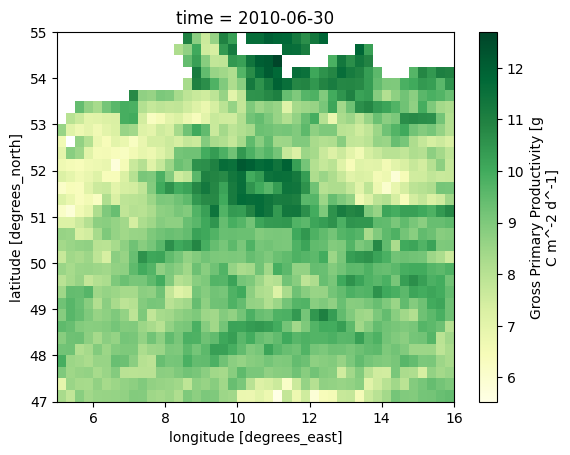

In [18]:
# Karte: GPP in Deutschland Anfang Juli 2010
gpp_de.sel(time='2010-07-01', method='nearest').plot(cmap='YlGn')
plt.show()

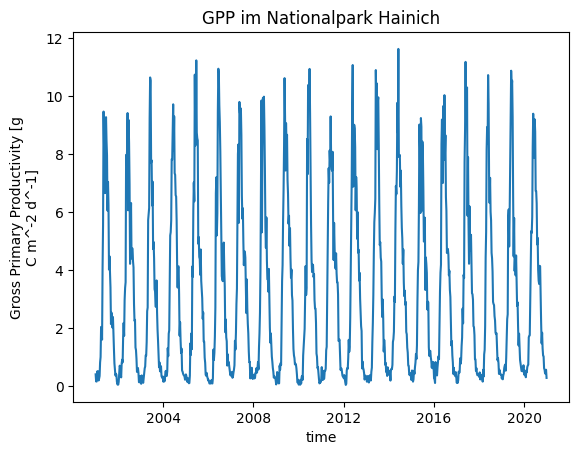

In [19]:
# Zeitreihe: GPP im Hainich
gpp_hainich.sel(time=slice('2001', '2020')).plot()
plt.title('GPP im Nationalpark Hainich')
plt.show()

Eine **globale Karte** für einen Zeitschritt geht auch.
Sie dauert aber deutlich länger, weil rund 1 GB geladen werden muss.

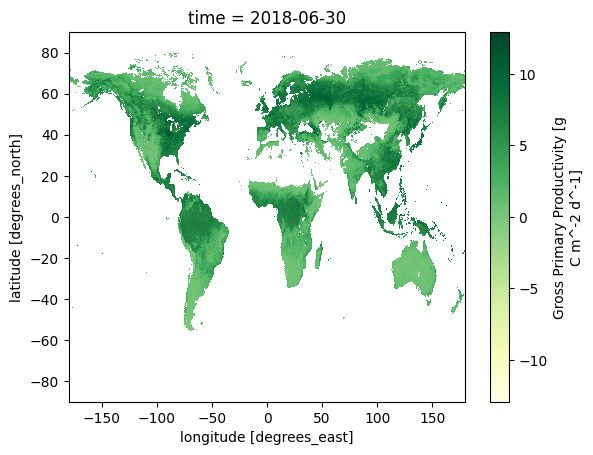

In [20]:
ds['gross_primary_productivity'].sel(time='2018-07-01', method='nearest').plot(cmap='YlGn')
plt.show()

Einzelne Ausreißer machen die Farbskala oft unbrauchbar.
`robust=True` nutzt dann das 2. und 98. Perzentil als Grenzen der Farbskala.
Mit `cmap` wählen wir die Farben. Übersicht: [Matplotlib Colormaps](https://matplotlib.org/stable/users/explain/colors/colormaps.html)

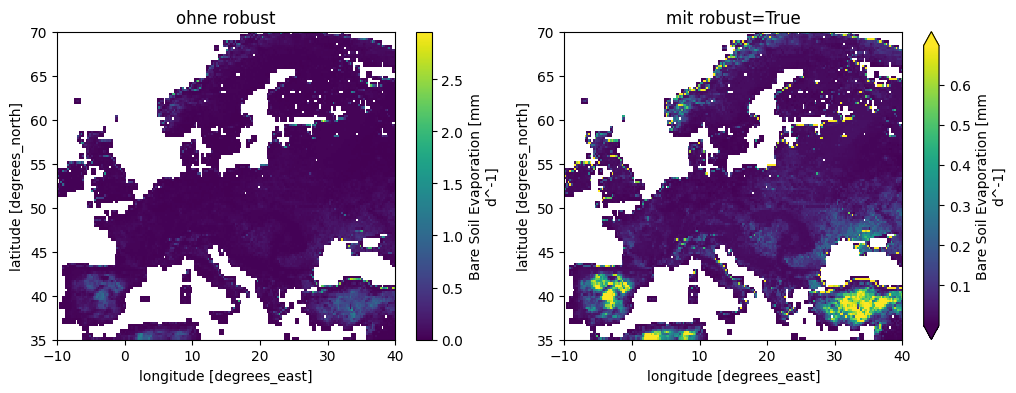

In [21]:
bse_europa = (ds['bare_soil_evaporation']
              .sel(lat=slice(35, 70), lon=slice(-10, 40))
              .sel(time='2010-07-01', method='nearest'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bse_europa.plot(ax=axes[0])
axes[0].set_title('ohne robust')
bse_europa.plot(ax=axes[1], robust=True)
axes[1].set_title('mit robust=True')
plt.show()

**Aufgabe:**
Karten verschiedener Variablen für eine Region erstellen.
Wie unterscheiden sich die Karten zu verschiedenen Zeitpunkten, z. B. im Januar und im Juli?

*Tipp:* Region und Zeitpunkt **vor** dem Plotten auswählen.

In [22]:
# Hier ausprobieren

## 7. Mittelwerte berechnen

Bei Mittelwerten ist die wichtigste Frage: **Über welche Dimension wird gemittelt?**
Diese Dimension verschwindet aus dem Ergebnis.

| Befehl | Ergebnis |
|---|---|
| `.mean('time')` | Karte (lat, lon) |
| `.mean(['lat', 'lon'])` | Zeitreihe (time) |
| `.groupby('time.month').mean()` | 12 Karten, eine pro Monat |

### 7.1 Mittel über die Zeit → Karte

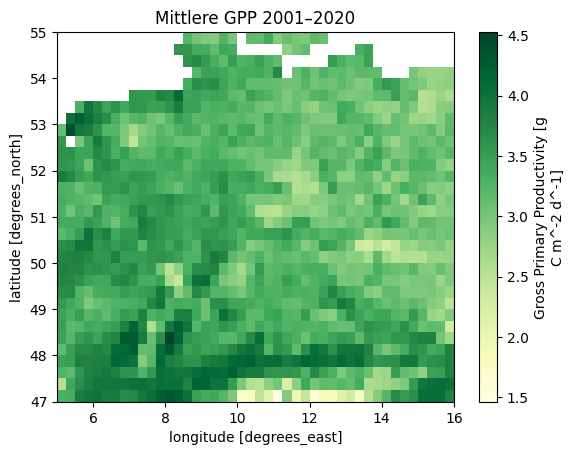

In [23]:
gpp_de_mittel = gpp_de.mean('time')

gpp_de_mittel.plot(cmap='YlGn')
plt.title('Mittlere GPP 2001–2020')
plt.show()

### 7.2 Mittel über den Raum → Zeitreihe

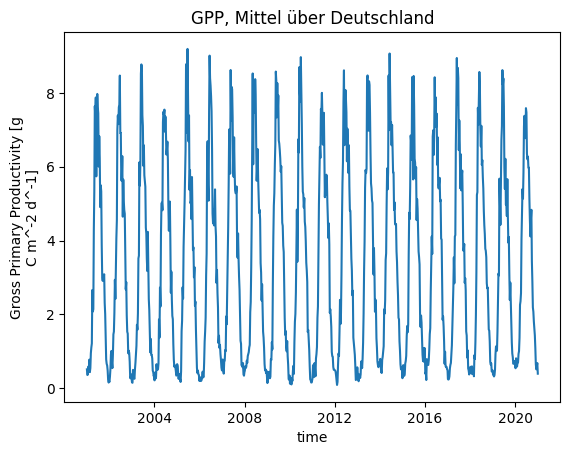

In [24]:
gpp_de_zeitreihe = gpp_de.mean(['lat', 'lon'])

gpp_de_zeitreihe.plot()
plt.title('GPP, Mittel über Deutschland')
plt.show()

### 7.3 Gewichtetes Mittel

**Frage:** In der Karte sind alle Gitterzellen gleich groß.
Auf der Erde stimmt das nicht.
Was passiert, wenn wir einfach den Mittelwert aller Zellen bilden?
Wie lässt sich das verbessern?

**Antwort:** Eine Gitterzelle von 0,25° × 0,25° ist am Äquator ca. 28 km × 28 km groß.
Zu den Polen hin wird sie immer schmaler.
Ihre Fläche nimmt mit dem **Kosinus des Breitengrads** ab.
Ein einfacher Mittelwert gewichtet die kleinen Zellen im Norden zu stark.

Deshalb gewichten wir jede Zelle mit `cos(lat)`.
`np.deg2rad()` rechnet vorher von Grad in Bogenmaß um.

Bei einer kleinen Region wie Deutschland ist der Unterschied gering.
Bei großen Regionen oder globalen Mitteln ist er deutlich.

In [25]:
gewichte = np.cos(np.deg2rad(gpp_de.lat))

gpp_de_gewichtet = gpp_de.weighted(gewichte).mean(['lat', 'lon'])

print(f'ungewichtet: {float(gpp_de_zeitreihe.mean()):.3f}')
print(f'gewichtet:   {float(gpp_de_gewichtet.mean()):.3f}')

ungewichtet: 3.306
gewichtet:   3.311


### 7.4 Mittlerer Jahresgang

`groupby('time.month')` sortiert alle Zeitschritte nach Monat.
Dann wird für jeden Monat über alle Jahre gemittelt.
Statt `time.month` geht auch `time.season` (Jahreszeit) oder `time.year` (Jahr).

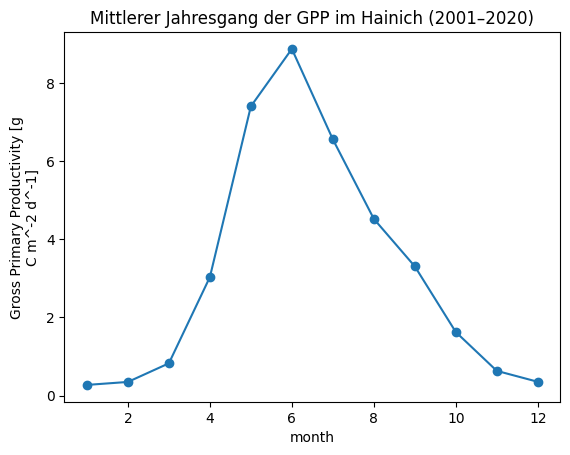

In [26]:
gpp_hainich_monat = gpp_hainich.sel(time=slice('2001', '2020')).groupby('time.month').mean()

gpp_hainich_monat.plot(marker='o')
plt.title('Mittlerer Jahresgang der GPP im Hainich (2001–2020)')
plt.show()

### 7.5 Jahresmittel

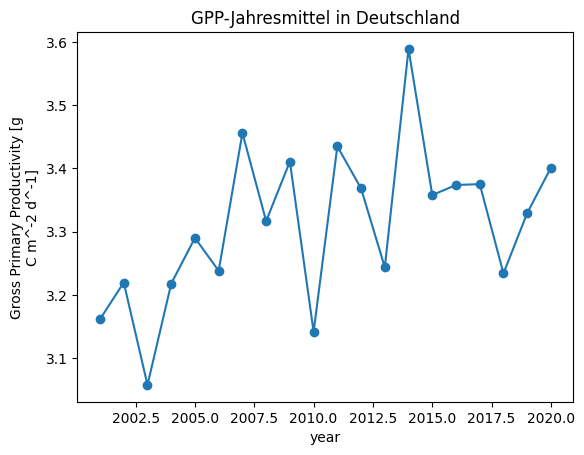

In [27]:
gpp_de_jahr = gpp_de_gewichtet.groupby('time.year').mean()

gpp_de_jahr.plot(marker='o')
plt.title('GPP-Jahresmittel in Deutschland')
plt.show()

### 7.6 Anomalien

Eine **Anomalie** ist die Abweichung vom Normalzustand.
Als Normalzustand nehmen wir den mittleren Jahresgang.
So wird sichtbar, wann die Vegetation weniger aktiv war als üblich, z. B. in einem Dürrejahr.

Die 8-Tage-Werte schwanken stark.
Deshalb bilden wir zuerst mit `resample` Monatsmittel.
Ein gleitendes Mittel über 12 Monate (`rolling`) macht längere Phasen sichtbar.

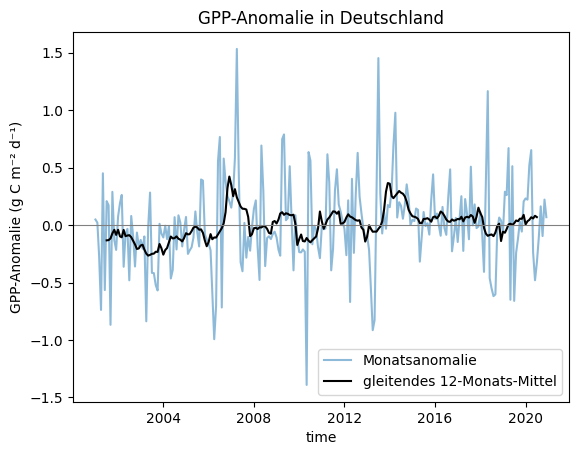

In [28]:
gpp_monat = gpp_de_gewichtet.resample(time='1MS').mean()   # ein Wert pro Monat und Jahr

klima = gpp_monat.groupby('time.month').mean()             # mittlerer Jahresgang (12 Werte)
anomalie = gpp_monat.groupby('time.month') - klima         # Abweichung davon

anomalie.plot(label='Monatsanomalie', alpha=0.5)
anomalie.rolling(time=12, center=True).mean().plot(label='gleitendes 12-Monats-Mittel', color='black')
plt.axhline(0, color='grey', linewidth=0.8)
plt.ylabel('GPP-Anomalie (g C m⁻² d⁻¹)')
plt.title('GPP-Anomalie in Deutschland')
plt.legend()
plt.show()

**Frage:** In welchen Jahren gibt es auffällig negative Anomalien?
Was könnte der Grund sein?

## 8. Masken

Mit `.where()` behalten wir nur Werte, die eine Bedingung erfüllen.
Alle anderen Werte werden zu `NaN`.

Der Cube enthält keine eigene Land-Wasser-Maske.
Variablen der Vegetation wie GPP gibt es aber nur über Land.
Damit lässt sich eine Maske bauen.

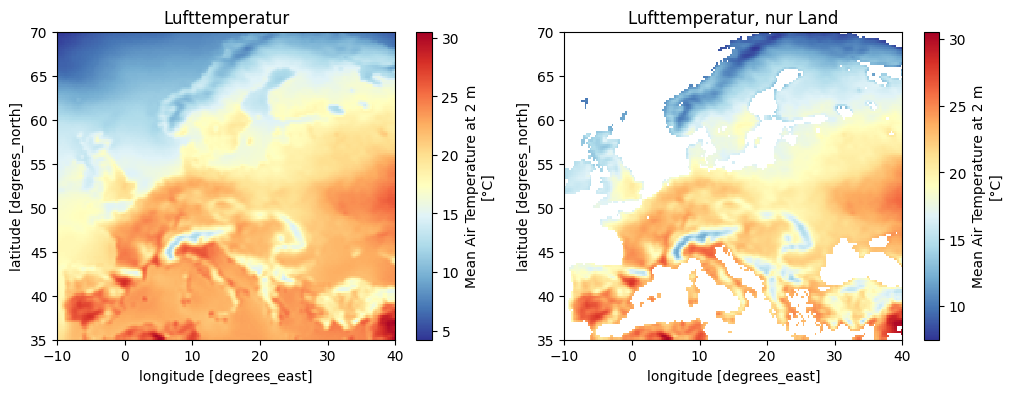

In [29]:
datum = '2010-07-01'
region = dict(lat=slice(35, 70), lon=slice(-10, 40))   # Europa

temp = ds['air_temperature_2m'].sel(time=datum, method='nearest').sel(**region)
gpp_eu = ds['gross_primary_productivity'].sel(time=datum, method='nearest').sel(**region)

landmaske = gpp_eu.notnull()          # True über Land, False über Wasser
temp_land = temp.where(landmaske)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
temp.plot(ax=axes[0], cmap='RdYlBu_r')
axes[0].set_title('Lufttemperatur')
temp_land.plot(ax=axes[1], cmap='RdYlBu_r')
axes[1].set_title('Lufttemperatur, nur Land')
plt.show()

## 9. Analyse: Wie ändert sich die GPP im Jahresverlauf?

Die **Bruttoprimärproduktion** (*gross primary productivity*, GPP) gibt an, wie viel Kohlenstoff Pflanzen durch Photosynthese aufnehmen.
Die Einheit im Cube ist Gramm Kohlenstoff pro Quadratmeter und Tag (g C m⁻² d⁻¹).

Wir wählen Europa und das Jahr 2007.
Dann berechnen wir den Mittelwert für jeden Monat.

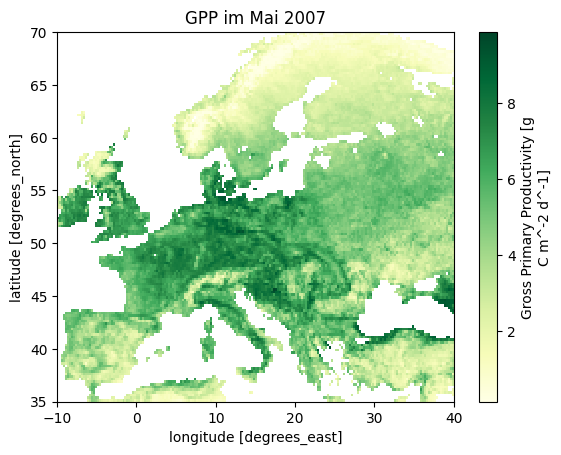

In [30]:
gpp_eu_2007 = ds['gross_primary_productivity'].sel(
    time='2007',
    lat=slice(35, 70),
    lon=slice(-10, 40),
).groupby('time.month').mean()

gpp_eu_2007.sel(month=5).plot(cmap='YlGn')
plt.title('GPP im Mai 2007')
plt.show()

Mit `col='month'` entsteht für jeden Monat eine eigene Karte.
`col_wrap=4` legt fest, wie viele Karten nebeneinander stehen.

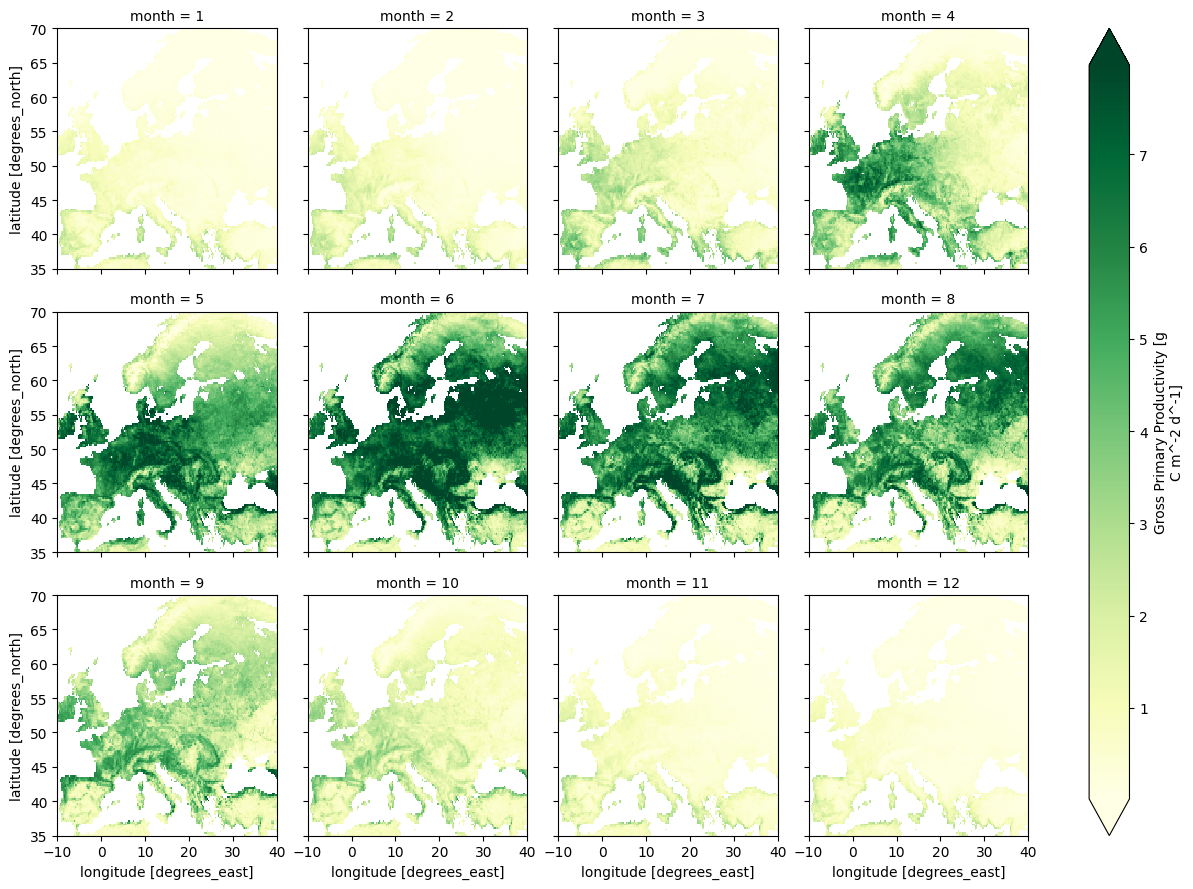

In [31]:
gpp_eu_2007.plot(col='month', col_wrap=4, cmap='YlGn', robust=True)
plt.show()

**Aufgabe (in Zweiergruppen):**
Eine andere Variable auswählen und die Analyse wiederholen.
Passt der Jahresgang zu den Erwartungen?

*Ideen:* `kndvi` (Vegetationsindex), `air_temperature_2m`, `precipitation_era5`, `sm` (Bodenfeuchte), `bare_soil_evaporation`

*Tipp:* Bei `.attrs` nachsehen, für welchen Zeitraum die Variable Daten hat.

In [32]:
# Hier die Lösung eintragen

**Lösung:** Erst selbst versuchen! Dann links auf die Zelle klicken, um den Code anzuzeigen.

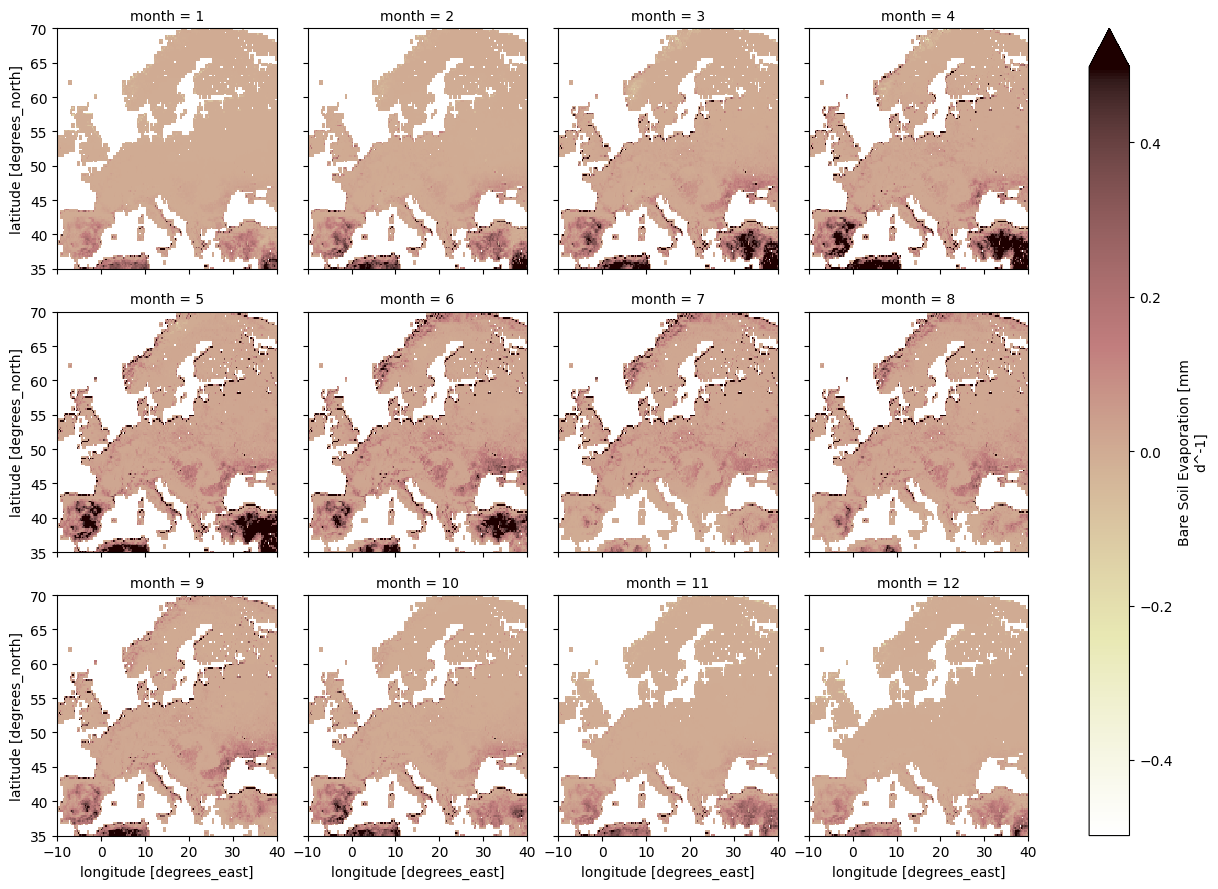

In [33]:
bse_eu_2007 = ds['bare_soil_evaporation'].sel(
    time='2007',
    lat=slice(35, 70),
    lon=slice(-10, 40),
).groupby('time.month').mean()

bse_eu_2007.plot(col='month', col_wrap=4, cmap='pink_r', robust=True)
plt.show()

## 10. Ergebnisse speichern

Ein geladener Ausschnitt lässt sich als netCDF-Datei speichern.
Dann muss er beim nächsten Mal nicht erneut geladen werden.
Im VRE bleiben Dateien im Home-Ordner auch nach einem Neustart erhalten.

In [34]:
gpp_de.to_netcdf('gpp_deutschland_2001-2020.nc')

# später wieder öffnen
gpp_de = xr.open_dataarray('gpp_deutschland_2001-2020.nc')
gpp_de

<xarray.DataArray 'gross_primary_productivity' (time: 920, lat: 32, lon: 44)> Size: 5MB
[1295360 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 7kB 2001-01-05 2001-01-13 ... 2020-12-30
  * lat      (lat) float64 256B 47.12 47.38 47.62 47.88 ... 54.38 54.62 54.88
  * lon      (lon) float64 352B 5.125 5.375 5.625 5.875 ... 15.38 15.62 15.88
Attributes: (12/25)
    acknowledgment:             FLUXCOM
    date_modified:              2022-10-17 22:14:30.401506
    description:                FLUXCOM
    geospatial_lat_max:         89.87499928049999
    geospatial_lat_min:         -89.8750000005
    geospatial_lat_resolution:  0.25
    ...                         ...
    standard_name:              gross_primary_productivity_of_carbon
    temporal_resolution:        8D
    time_coverage_end:          2020-12-30T00:00:00.000000000
    time_coverage_start:        2001-01-05T00:00:00.000000000
    time_period:                8D
    units:                      g C m^-2 d^-1

---

## Weiterführendes Material

- [Xarray-Dokumentation](https://docs.xarray.dev/en/stable/) mit [User Guide](https://docs.xarray.dev/en/stable/user-guide/index.html)
- [Xarray in 45 Minuten](https://tutorial.xarray.dev/overview/xarray-in-45-min.html) (Tutorial)
- [Terminologie](https://docs.xarray.dev/en/stable/user-guide/terminology.html) und [Plotten](https://docs.xarray.dev/en/stable/user-guide/plotting.html)
- [Zeitreihen mit Xarray](https://docs.xarray.dev/en/stable/user-guide/time-series.html): `groupby`, `resample` und mehr
- [Earth System Data Lab](https://www.earthsystemdatalab.net/): Hintergrund zum Cube